# Task 2: Qwen3-ASR-1.7B for Speech-to-Text
**Before running:** Runtime → Change runtime type → **T4 GPU**. Then run the cells in order.
All numbers in the report must come from the outputs of this notebook (no hand-typed results).

## 1. Environment check (GPU, PyTorch, memory)

In [1]:
import torch, platform, sys

print("Python:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "No GPU! Runtime > Change runtime type > T4 GPU, then restart and run again."

gpu_name = torch.cuda.get_device_name(0)
gpu_total = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
print("GPU:", gpu_name)
print("GPU Memory:", gpu_total, "GB")

Python: 3.13.16
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


## 2. Install libraries

In [2]:
!pip install -U qwen-asr jiwer -q
import importlib.metadata as md
print("qwen-asr:", md.version("qwen-asr"))
print("jiwer:", md.version("jiwer"))
print("transformers:", md.version("transformers"))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
qwen-asr: 0.0.6
jiwer: 4.0.0
transformers: 4.57.6


## 3. Load the model (FP16 on CUDA) and measure its GPU memory

In [3]:
import time, torch
from qwen_asr import Qwen3ASRModel

t0 = time.perf_counter()
model = Qwen3ASRModel.from_pretrained(
    "Qwen/Qwen3-ASR-1.7B",
    dtype=torch.float16,
    device_map="cuda:0",
)
load_time = time.perf_counter() - t0

torch.cuda.synchronize()
model_memory = torch.cuda.memory_allocated() / 1024**3
reserved_memory = torch.cuda.memory_reserved() / 1024**3
print("Model loaded successfully!")
print(f"Model load time:      {load_time:.1f} s")
print(f"Model GPU memory:     {model_memory:.2f} GB (allocated)")
print(f"Reserved GPU memory:  {reserved_memory:.2f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.22G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/478M [00:00<?, ?B/s]

... (5 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

Model loaded successfully!
Model load time:      68.4 s
Model GPU memory:     3.80 GB (allocated)
Reserved GPU memory:  4.41 GB


## 4. Samples and ground truth
Fill in **one row per recording**: the file name (upload the files to Colab first), the language,
a short description of the condition, and the **manually written reference text**.

⚠️ Write the reference **by hand** (or from the original script of the recording). Do not copy it from a web page/chat window:
in the earlier version the reference of the noisy sample ended with the words "Copy text" (copied from the chat UI), which are not spoken in the audio.

In [4]:
samples = [
    {"id": 1, "file": "English1.m4a",   "language": "English", "condition": "English, first speaker",
     "reference": "Hello, my name is Maymona. I am a computer systems engineering graduate, and I am interested in artificial intelligence and software development. Recently, I have been working on projects that use large language models to process information, answer questions, and analyze data. I believe artificial intelligence can make our daily work easier and help us solve complex problems. I am excited to learn more about speech recognition and natural language processing."},
    {"id": 2, "file": "English2.m4a",  "language": "English", "condition": "English, second speaker",
     "reference": "Technology is changing the way people communicate, learn, and work. Speech recognition systems can convert spoken language into written text, making information more accessible. However, recognizing speech is not always easy. Different accents, speaking speeds, background noise, and pronunciation can affect transcription quality. Modern artificial intelligence models are designed to handle these challenges and provide more accurate results."},
    {"id": 3, "file": "Test_with_noise.m4a",  "language": "English", "condition": "English with background noise",
     "reference": "Our daily lives. People use artificial intelligence to communicate, solve problems, and access information. Speech recognition systems must understand different voices even when the recording environment is not completely quiet. Background noise can make it more difficult to recognize individual words accurately."},
    {"id": 4, "file": "EnglishDifferentAccent.m4a",  "language": "English", "condition": "English with a different accent",
     "reference": "Artificial intelligence is transforming many industries, including education, healthcare, and technology. Voice recognition allows computers to understand spoken instructions and respond to users. However, people pronounce words differently depending on their language background and regional accent. Testing different accents helps us understand how well speech recognition models perform in real-world situations."},
    {"id": 5, "file": "PalestinianArabic.m4a",  "language": "Arabic",  "condition": "Arabic speech",
     "reference": "الذكاء الاصطناعي صار جزء مهم من حياتنا اليومية. بنستخدمه في التعليم والصحة والتكنولوجيا، وبساعدنا ننجز كثير من المهام بطريقة أسرع وأسهل. كمان تقنيات التعرف على الصوت بتسمح للأجهزة إنها تفهم كلامنا وتحوله إلى نص مكتوب، لكن أحياناً اختلاف اللهجات وطريقة النطق ممكن يأثر على دقة النتائج."},
    {"id": 6, "file": "StandardArabic.m4a",  "language": "Arabic",  "condition": "Arabic speech",
     "reference": "أصبحت تقنيات الذكاء الاصطناعي جزءاً أساسياً من حياتنا اليومية. فهي تُستخدم في مجالات متعددة مثل التعليم والطب والصناعة. وتساعد أنظمة التعرف على الكلام في تحويل الصوت إلى نص مكتوب، مما يسهل الوصول إلى المعلومات. ومع ذلك، تختلف دقة هذه الأنظمة حسب جودة التسجيل وسرعة المتحدث وطريقة نطق الكلمات."},
    {"id": 7, "file": "FastEngilsh.m4a",  "language": "English", "condition": "Fast English speech",
     "reference": "Technology has become an important part of our daily lives. People use artificial intelligence to communicate, solve problems, and access information. Speech recognition systems must understand different voices even when the recording environment is not completely quiet. Background noise can make it more difficult to recognize individual words accurately."},
]
print(len(samples), "samples defined")

7 samples defined


## 5. Upload the audio files

In [13]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving English1.m4a to English1 (1).m4a
Saving English2.m4a to English2 (1).m4a
Saving EnglishDifferentAccent.m4a to EnglishDifferentAccent (1).m4a
Saving FastEngilsh.m4a to FastEngilsh (1).m4a
Saving PalestinianArabic.m4a to PalestinianArabic (1).m4a
Saving StandardArabic.m4a to StandardArabic (1).m4a
Saving Test_with_noise.m4a to Test_with_noise (1).m4a
Uploaded: ['English1 (1).m4a', 'English2 (1).m4a', 'EnglishDifferentAccent (1).m4a', 'FastEngilsh (1).m4a', 'PalestinianArabic (1).m4a', 'StandardArabic (1).m4a', 'Test_with_noise (1).m4a']


## 6. Evaluation helpers
Two versions of each metric are computed:
* **Raw**: exactly the strings as they are (this is what the first version of the notebook did).
* **Normalized**: lowercase, punctuation removed, extra spaces removed (and for Arabic: diacritics removed and أ/إ/آ → ا).
  This measures recognition errors only, without penalizing casing/punctuation differences.

Decide which one goes in the report and **say it in the paper**. Report the other one as a remark if you like.

In [6]:
import re, time, unicodedata
import soundfile as sf
import librosa
from jiwer import wer, cer

def normalize(text, language):
    text = unicodedata.normalize("NFKC", text).strip()
    if language == "Arabic":
        text = re.sub(r"[\u064B-\u0652\u0640]", "", text)
        text = re.sub(r"[إأآ]", "ا", text)
    else:
        text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def audio_duration(path):
    try:
        return sf.info(path).duration
    except Exception:
        return librosa.get_duration(path=path)

def run_sample(s, warmup=False):
    path = s["file"]
    dur = audio_duration(path)
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = model.transcribe(audio=path, language=s["language"])
    torch.cuda.synchronize()
    t = time.perf_counter() - t0
    hyp = out[0].text
    peak = torch.cuda.max_memory_allocated() / 1024**3
    return dict(hyp=hyp, time=t, duration=dur, peak_mem=peak)

## 7. Warm-up run (not counted)
The first call to the GPU is slower (CUDA kernels initialisation), which can make the first sample look slower than it is.
A warm-up call makes the inference-time comparison fair.

In [7]:
_ = run_sample(samples[0])
print("Warm-up done")

/tmp/ipykernel_903/3743008628.py:21: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  return librosa.get_duration(path=path)   # fallback for m4a
/usr/local/lib/python3.13/dist-packages/qwen_asr/inference/utils.py:146: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(x, sr=None, mono=False)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Warm-up done


## 8. Run all samples

In [8]:
import pandas as pd

rows, details = [], []
for s in samples:
    if s["reference"].startswith(("PASTE", "الصقي")):
        print(f"Sample {s['id']}: reference not filled yet, skipped"); continue
    r = run_sample(s)
    ref_n, hyp_n = normalize(s["reference"], s["language"]), normalize(r["hyp"], s["language"])
    rows.append({
        "Sample": s["id"], "Audio File": s["file"], "Language": s["language"], "Condition": s["condition"],
        "Duration (s)": round(r["duration"], 2),
        "WER raw (%)": round(wer(s["reference"], r["hyp"]) * 100, 2),
        "CER raw (%)": round(cer(s["reference"], r["hyp"]) * 100, 2),
        "WER norm (%)": round(wer(ref_n, hyp_n) * 100, 2),
        "CER norm (%)": round(cer(ref_n, hyp_n) * 100, 2),
        "Inference Time (s)": round(r["time"], 2),
        "RTF": round(r["time"] / r["duration"], 3),
        "Peak GPU mem (GB)": round(r["peak_mem"], 2),
    })
    details.append({"id": s["id"], "language": s["language"], "reference": s["reference"], "hypothesis": r["hyp"]})
    print(f"Sample {s['id']} done: {r['time']:.2f}s for {r['duration']:.1f}s of audio")

results = pd.DataFrame(rows)
results

/tmp/ipykernel_903/3743008628.py:21: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  return librosa.get_duration(path=path)   # fallback for m4a
/usr/local/lib/python3.13/dist-packages/qwen_asr/inference/utils.py:146: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(x, sr=None, mono=False)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Sample 1 done: 4.50s for 44.3s of audio


/tmp/ipykernel_903/3743008628.py:21: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  return librosa.get_duration(path=path)   # fallback for m4a
/usr/local/lib/python3.13/dist-packages/qwen_asr/inference/utils.py:146: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(x, sr=None, mono=False)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Sample 2 done: 3.91s for 28.3s of audio


/tmp/ipykernel_903/3743008628.py:21: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  return librosa.get_duration(path=path)   # fallback for m4a
/usr/local/lib/python3.13/dist-packages/qwen_asr/inference/utils.py:146: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(x, sr=None, mono=False)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Sample 3 done: 2.47s for 21.3s of audio


... (5 outputs left out)

Sample 6 done: 4.97s for 24.9s of audio


/tmp/ipykernel_903/3743008628.py:21: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  return librosa.get_duration(path=path)   # fallback for m4a
/usr/local/lib/python3.13/dist-packages/qwen_asr/inference/utils.py:146: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(x, sr=None, mono=False)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


Sample 7 done: 2.81s for 22.0s of audio


,Sample,Audio File,Language,Condition,Duration (s),WER raw (%),CER raw (%),WER norm (%),CER norm (%),Inference Time (s),RTF,Peak GPU mem (GB)
0,1,English1.m4a,English,"English, first speaker",44.3,1.41,0.65,1.41,0.66,4.50,0.102,4.14
1,2,English2.m4a,English,"English, second speaker",28.3,0.00,0.00,0.00,0.00,3.91,0.138,4.03
2,3,Test_with_noise.m4a,English,English with background noise,21.3,7.14,0.96,0.00,0.00,2.47,0.116,4.01
3,4,EnglishDifferentAccent.m4a,English,English with a different accent,42.9,1.96,1.69,1.92,1.72,3.25,0.076,4.13
4,5,PalestinianArabic.m4a,Arabic,Arabic speech,24.6,13.04,3.17,8.70,2.16,6.02,0.245,4.03
5,6,StandardArabic.m4a,Arabic,Arabic speech,24.9,12.50,2.74,2.08,1.06,4.97,0.200,4.03
6,7,FastEngilsh.m4a,English,Fast English speech,22.0,2.04,0.28,0.00,0.00,2.81,0.128,4.02


**RTF (Real-Time Factor)** = processing time ÷ audio duration. If RTF < 1 the model is faster than real time
(like a runner who finishes a 10-minute route in 4 minutes). It is a fairer speed metric than raw seconds because the recordings have different lengths.

## 9. Input / output examples (reference vs. model output)

In [9]:
for d in details:
    print(f"--- Sample {d['id']} ({d['language']}) ---")
    print("REF:", d["reference"])
    print("HYP:", d["hypothesis"])
    print()

--- Sample 1 (English) ---
REF: Hello, my name is Maymona. I am a computer systems engineering graduate, and I am interested in artificial intelligence and software development. Recently, I have been working on projects that use large language models to process information, answer questions, and analyze data. I believe artificial intelligence can make our daily work easier and help us solve complex problems. I am excited to learn more about speech recognition and natural language processing.
HYP: Hello, my name is Meimuna. I am a computer systems engineering graduate, and I am interested in artificial intelligence and software development. Recently, I have been working on projects that use large language models to process information, answer questions, and analyze data. I believe artificial intelligence can make our daily work easier and help us solve complex problems. I am excited to learn more about speech recognition and natural language processing.

--- Sample 2 (English) ---
REF: 

## 10. Summary statistics (these are the numbers for the report)

In [10]:
cols = ["WER raw (%)", "CER raw (%)", "WER norm (%)", "CER norm (%)", "Inference Time (s)", "RTF"]
print("=== Overall average ===")
print(results[cols].mean().round(2))

print("\n=== Average by language ===")
print(results.groupby("Language")[cols].mean().round(2))

print("\n=== Average without the noisy sample (id 3) ===")
print(results[results["Sample"] != 3][cols].mean().round(2))

print("\nBest sample (lowest raw WER):");  print(results.loc[results["WER raw (%)"].idxmin(), ["Sample", "Condition", "WER raw (%)"]].to_dict())
print("Worst sample (highest raw WER):"); print(results.loc[results["WER raw (%)"].idxmax(), ["Sample", "Condition", "WER raw (%)"]].to_dict())

=== Overall average ===
WER raw (%)           5.44
CER raw (%)           1.36
WER norm (%)          2.02
CER norm (%)          0.80
Inference Time (s)    3.99
RTF                   0.14
dtype: float64

=== Average by language ===
          WER raw (%)  CER raw (%)  WER norm (%)  CER norm (%)  \
Language                                                         
Arabic          12.77         2.96          5.39          1.61   
English          2.51         0.72          0.67          0.48   

          Inference Time (s)   RTF  
Language                            
Arabic                  5.49  0.22  
English                 3.39  0.11  

=== Average without the noisy sample (id 3) ===
WER raw (%)           5.16
CER raw (%)           1.42
WER norm (%)          2.35
CER norm (%)          0.93
Inference Time (s)    4.24
RTF                   0.15
dtype: float64

Best sample (lowest raw WER):
{'Sample': 2, 'Condition': 'English, second speaker', 'WER raw (%)': 0.0}
Worst sample (highest raw 

## 11. Chart (WER/CER per sample) and LaTeX table

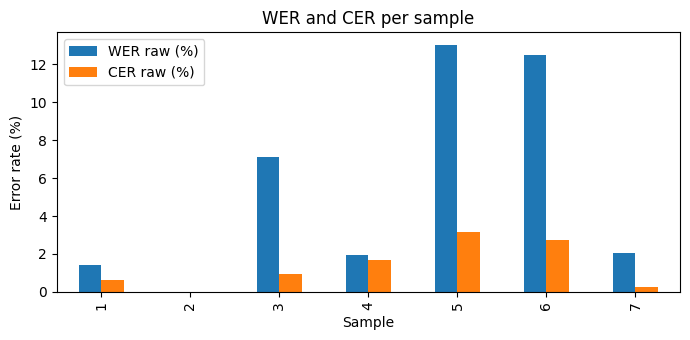

% --- paste inside the tabular of the results table ---
1 & English & 1.41 & 0.65 & 4.50 \\
2 & English & 0.00 & 0.00 & 3.91 \\
3 & English & 7.14 & 0.96 & 2.47 \\
4 & English & 1.96 & 1.69 & 3.25 \\
5 & Arabic & 13.04 & 3.17 & 6.02 \\
6 & Arabic & 12.50 & 2.74 & 4.97 \\
7 & English & 2.04 & 0.28 & 2.81 \\
\midrule
Average & -- & 5.44 & 1.36 & 3.99 \\


In [11]:
import matplotlib.pyplot as plt

ax = results.set_index("Sample")[["WER raw (%)", "CER raw (%)"]].plot(kind="bar", figsize=(7, 3.5))
ax.set_ylabel("Error rate (%)"); ax.set_title("WER and CER per sample"); plt.tight_layout()
plt.savefig("wer_cer_per_sample.png", dpi=200)
plt.show()

print("% --- paste inside the tabular of the results table ---")
for _, r in results.iterrows():
    print(f"{int(r['Sample'])} & {r['Language']} & {r['WER raw (%)']:.2f} & {r['CER raw (%)']:.2f} & {r['Inference Time (s)']:.2f} \\\\")
print("\\midrule")
print(f"Average & -- & {results['WER raw (%)'].mean():.2f} & {results['CER raw (%)'].mean():.2f} & {results['Inference Time (s)'].mean():.2f} \\\\")

## 12. Save everything

In [12]:
import json
results.to_csv("asr_results.csv", index=False)
with open("transcriptions.json", "w", encoding="utf-8") as f:
    json.dump(details, f, ensure_ascii=False, indent=2)

env = {
    "gpu": gpu_name, "gpu_total_gb": gpu_total, "torch": torch.__version__,
    "qwen_asr": md.version("qwen-asr"), "model_gpu_memory_gb": round(model_memory, 2),
    "model_load_time_s": round(load_time, 1),
}
print(env)

files.download("asr_results.csv")
files.download("transcriptions.json")
files.download("wer_cer_per_sample.png")

{'gpu': 'Tesla T4', 'gpu_total_gb': 14.56, 'torch': '2.14.1+cu130', 'qwen_asr': '0.0.6', 'model_gpu_memory_gb': 3.8, 'model_load_time_s': 68.4}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>